In [5]:
# Timer for notebook
import time
_start_time = time.perf_counter()

# Put imports here
import numpy as np
from scipy import stats, special, integrate, fft
import matplotlib.pyplot as plt
import mp3lib as ml

SEED = 690403480 # drawn 2026-11-23, do not change
rng = np.random.default_rng(SEED)
rng_1, rng_2, rng_3, rng_4, rng_5, rng_6, rng_7, rng_8, rng_A, rng_B = rng.spawn(10)

magnitude = 6
n = np.zeros(magnitude + 1, dtype=int)
for i in range(magnitude + 1):
    n[i] = 10 ** i

## Step 1

Let (𝑋, 𝑌 ) have the joint density:

$$
f_{XY} (x,y) =  x + y, \ \ \ \ \ 0\leq x \leq 1, 0\leq y \leq 1
$$

**Hand in.** Figure 1, three panels: a filled contour or heatmap of the joint density, the two marginals with
analytic and numerical curves overlaid, and the conditional at 𝑥 = 0.3.

**Check yourself.** 

𝐸[𝑋] = 𝐸[𝑌 ] = 7/12 = 0.583333.
 
𝐸[𝑋𝑌 ] = 1/3. 

Var(𝑋) = 11/144 = 0.0763889.

Cov(𝑋, 𝑌 ) = −1/144 = −0.00694444. 

𝜌 = −1/11 = −0.0909091. 

The marginal is 𝑓𝑋(𝑥) = 𝑥 + 1/2, so 𝑓𝑋(0.3) = 0.8.

### 1. Verify by hand that this is a valid density, then confirm it numerically with a 2D quadrature.

*To verify by hand, a valid density must have volume = 1*

$$ \int^1_0 \int^1_0 (x+y) \, dxdy $$

$$ \int^1_0 \left[ \frac{x^2}{2} + y \right]^1_0 \, dy = \int^1_0 (\frac{1}{2} + y) \, dy $$

$$ \int^1_0 (\frac{1}{2} + y) \, dy $$

$$ \boxed{ \left[ \frac{1}{2} + \frac{y^2}{2} \right]^1_0 \,  = \frac{1}{2} + \frac{1}{2} = 1} $$

In [95]:
# Verifying numerically via 2D quadrature

from scipy.integrate import dblquad

def f_xy(y, x):
  return x + y

val, err = dblquad(
    f_xy,
    0,
    1,  
    lambda x: 0,
    lambda x: 1,
)

print(f"Double integral is evaluated to:\t{val}\n" + 
      f"Estimated error:\t\t\t{err:.3e}")

Double integral is evaluated to:	1.0
Estimated error:			1.663e-14


### 2. Derive both marginals by hand. Confirm each numerically by integrating the joint density over the other variable on a grid, and overlay the numerical marginal on the analytic on

*Marginal Density of X*

$$ f_X(x) = \int^1_0 (x + y) \, dy = \left[ xy + \frac{y^2}{2} \right]^1_0 $$

$$ \boxed{f_X(x) = x + \frac{1}{2}} $$

___

*Marginal Density of Y*

$$ f_Y(y) = \int^1_0 (x + y) \, dx = \left[ \frac{x^2}{2} + xy  \right]^1_0 $$

$$ \boxed{f_Y(y) = x + \frac{1}{2}} $$

In [96]:
# grid for x and y
grid = np.linspace(0, 1, 200)
X, Y = np.meshgrid(grid, grid, indexing='ij')

# joint pdf
F_xy = X + Y

# numerical marginals using np.trapezoid
f_x_num = np.trapezoid(F_xy, grid, axis=1)
f_y_num = np.trapezoid(F_xy, grid, axis=0)

# analytic marginals
f_x_analytic = grid + 0.5
f_y_analytic = grid + 0.5

# fig 1 being made
fig1, axes = plt.subplots(1, 3, figsize=(15, 4))

hm = axes[0].pcolormesh(X, Y, Z, cmap="viridis", shading="auto")

fig1.colorbar(hm, ax=axes[0], label=r"$f_{XY}(x, y)$")
axes[0].set_title("Continuous Heatmap ")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("$y$")
axes[0].set_aspect("equal")

# Marginal of X
axes[1].plot(
    grid, f_x_analytic, label='Analytic $f_X(x) = x + 0.5$', linewidth=1.5, color='b'
)
axes[1].plot(
    grid[::10],
    f_x_num[::10],
    'o',
    # color='r',
    label='X (Numerical)',
    markersize=3,
)

# Marginal of Y
axes[1].plot(
    grid, f_y_analytic, label='Analytic $f_Y(y) = y + 0.5$', linewidth=1, color='r'
)
axes[1].plot(
    grid[::10],
    f_y_num[::10],
    'o',
    label='Y (Numerical)',
    markersize=2,
)
axes[1].set_title('Marginal Density of $X$ and $Y$')
axes[1].set_xlabel('$x$ or $y$')
axes[1].set_ylabel('$f_X(x)$ or $f_Y(y)$')
axes[1].set_ylim(0, 1.7)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig1.tight_layout()
plt.close(fig1)

### 3. Derive the conditional density of 𝑌 given 𝑋 = 𝑥. Evaluate it at 𝑥 = 0.3 and plot it. Confirm it integrates to 1.

*Conditional Density of 𝑌 given 𝑋 = 𝑥*

$$ f_{Y|X}(y|x) = \frac{x+y}{x+0.5} $$

___

*At 𝑥 = 0.3:*

$$ f_{Y|X}(y|0.3) = \frac{0.3+y}{0.3+0.5} =  \frac{0.3+y}{0.8} $$

$$ \text{at y=0:} \ \ \ f_{Y|X}(0|0.3) $$

$$ \text{at y=1:} \ \ \ f_{Y|X}(1|0.3) $$

___

*Conditional Density integrating to 1*

$$ \int^1_0 f_{Y|X}(y|0.3) \, dy = \int^1_0 \frac{x+y}{x+0.5} \, dy $$

$$ \int^1_0 \frac{x+y}{x+0.5} \, dy = \frac{1}{0.8} \left[ 0.3y + \frac{y^2}{2}\right]^1_0 = $$

$$\boxed{\frac{1}{0.8}(0.3+\frac{1}{2}) = 1}$$

Integral of f_(Y|X)(y | 0.3):	0.9999999999999999
Estimated error:		1.110e-14
At x=0.3, conditional density does still integrate to 1.


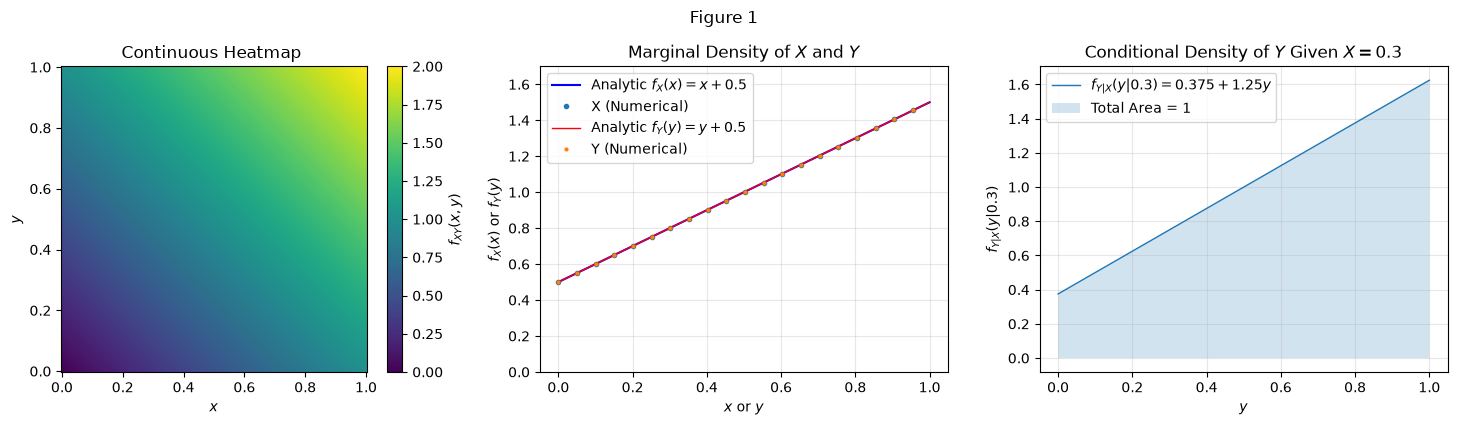

In [97]:
from scipy.integrate import quad

x_val = 0.3
f_y_given_x = lambda y: (x_val + y) / (x_val + 0.5)

area, err = quad(f_y_given_x, 0, 1)

print(f"Integral of f_(Y|X)(y | 0.3):\t{area}\n" + f"Estimated error:\t\t{err:.3e}")
print(f"At x=0.3, conditional density does still integrate to 1.")

# 2. conditional density at x=0.3
y = np.linspace(0, 1, 200)
pdf_vals = f_y_given_x(y)

axes[2].plot(y, pdf_vals, linewidth=1, label=r"$f_{Y|X}(y | 0.3) = 0.375 + 1.25y$", markersize=10)
axes[2].fill_between(y, pdf_vals, alpha=0.2, label="Total Area = 1")
axes[2].set_title("Conditional Density of $Y$ Given $X = 0.3$")
axes[2].set_xlabel("$y$")
axes[2].set_ylabel("$f_{Y|X}(y | 0.3)$")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

fig1.suptitle('Figure 1', y=1.05)
fig1

*Continuous Heatmap*

The continuous heatmap provides a smooth interpretation of the outcomes of the probability. It shows a negative correlation between x and y, where as one becomes a higher number, it's likely that the other is lower. This is found as the gradient

*Marginal Density of X and Y*

Both x and y form the same linear line that have a positive slope, both in the analytical and numerical plots. The analytic and numerical values of so match exactly, that all 4 plots (the analytic and numerical marginals of x and y), lay on top of each other.

*Conditional Density of Y Given X = 0.3*

When providing X = 0.3, it creates essentially a slice from the heatmap and provides a density that is more easily represneted by a line on a 2d graph. As X is fixed to a smaller value, Y is shown to be pulled upward and thus creates a steeper slope in the graph.

### 4. Compute 𝐸[𝑋], 𝐸[𝑌], 𝐸[𝑋𝑌], Var(𝑋), Cov(𝑋, 𝑌) and the correlation coefficient, all by hand, and verify each by quadrature.

*Computing 𝐸[𝑋] and 𝐸[𝑌]* 

$$
\begin{align*}
E[X] &= \int_0^1 x \left(x + \frac{1}{2}\right) dx \\
     &= \int_0^1 \left(x^2 + \frac{1}{2}x\right) dx \\
     &= \left[ \frac{x^3}{3} + \frac{x^2}{4} \right]_0^1 \\
     &= \frac{1}{3} + \frac{1}{4} = \boxed{\frac{7}{12} = 0.583}
\end{align*} \\
\text{Due to symmetry: }\ \boxed{E[Y] = \frac{7}{12} = 0.583}
$$

___

*Computing 𝐸[𝑋𝑌]*

$$
\begin{align*}
E[XY] &= \int_0^1 \int_0^1 xy(x + y) \, dx \, dy \\
      &= \int_0^1 \left[ \frac{x^3}{3}y + \frac{x^2}{2}y^2 \right]_{x=0}^{x=1} dy \\
      &= \int_0^1 \left( \frac{1}{3}y + \frac{1}{2}y^2 \right) dy \\
      &= \left[ \frac{y^2}{6} + \frac{y^3}{6} \right]_0^1 \\
      &= \boxed{\frac{1}{6} + \frac{1}{6} = \frac{1}{3} = 0.333}
\end{align*}
$$

___

*Computing Var(𝑋)*

$$
\begin{align*}
E[X^2] &= \int_0^1 x^2 \left(x + \frac{1}{2}\right) dx \\
       &= \left[ \frac{x^4}{4} + \frac{x^3}{6} \right]_0^1 \\ 
       &= \frac{1}{4} + \frac{1}{6} = \frac{5}{12}
\end{align*}
\\
\\
\begin{align*}
Var(X) &= E[X^2] - (E[X])^2 \\
&= \frac{5}{12} - \left(\frac{7}{12}\right)^2 \\
&= \frac{60 - 49}{144} \\
&= \boxed{\frac{11}{144}}
\end{align*}
$$

___

*Computing Cov(𝑋, 𝑌)*

$$
\begin{align*}
Cov(X, Y) &= E[XY] - E[X]E[Y] \\
          &= \frac{1}{3} - \left(\frac{7}{12}\right)\left(\frac{7}{12}\right) \\
          &= \boxed{\frac{48 - 49}{144} = -\frac{1}{144}}
\end{align*}
$$

In [98]:
def f_xy(y, x):
  return x + y

#exact values
ex = 7/12
ey = 7/12
exy = 1/3
varx = 11/144
covxy = -1/144

EX, _ = dblquad(lambda y, x: x * f_xy(y, x), 0, 1, 0, 1)
EY, _ = dblquad(lambda y, x: y * f_xy(y, x), 0, 1, 0, 1)
EXY, _ = dblquad(lambda y, x: x * y * f_xy(y, x), 0, 1, 0, 1)
EX2, _ = dblquad(lambda y, x: (x**2) * f_xy(y, x), 0, 1, 0, 1)
EY2, _ = dblquad(lambda y, x: (y**2) * f_xy(y, x), 0, 1, 0, 1)

VarX = EX2 - EX**2
CovXY = EXY - EX * EY

print(f"E[X]      = {EX:.6f}\t | Exact: {ex:.6f}\t | %Error: {(abs(EX-ex)/ex)*100:.6e}")
print(f"E[Y]      = {EY:.6f}\t | Exact: {ey:.6f}\t | %Error: {(abs(EY-ey)/ey)*100:.6e}")
print(f"E[XY]     = {EXY:.6f}\t | Exact: {exy:.6f}\t | %Error: {(abs(EXY-exy)/exy)*100:.6e}")
print(f"Var(X)    = {VarX:.6f}\t | Exact: {varx:.6f}\t | %Error: {(abs(VarX-varx)/varx)*100:.6e}")
print(f"Cov(X, Y) = {CovXY:.6f}\t | Exact: {corxy:.6f}\t | %Error: {(abs(CovXY-covxy)/covxy)*100:.6e}")

E[X]      = 0.583333	 | Exact: 0.583333	 | %Error: 1.903239e-14
E[Y]      = 0.583333	 | Exact: 0.583333	 | %Error: 1.903239e-14
E[XY]     = 0.333333	 | Exact: 0.333333	 | %Error: 3.330669e-14
Var(X)    = 0.076389	 | Exact: 0.076389	 | %Error: 7.266914e-14
Cov(X, Y) = -0.006944	 | Exact: -0.006944	 | %Error: -2.747802e-12


### 5. Generate 10<sup>6</sup> samples from this joint density by rejection sampling, and confirm your sample statistics against the analytic values with standard errors. State your acceptance rate and explain how you chose the bounding constant.

In [99]:
N_target = n[6]
M = 2.0

# Generate samples in batches until we collect exactly 10^6 accepted pairs
x_accepted = []
y_accepted = []
total_proposed = 0

while sum(len(chunk) for chunk in x_accepted) < N_target:
  batch_size = 500_000
  x_cand = rng_1.uniform(0.0, 1.0, size=batch_size)
  y_cand = rng_1.uniform(0.0, 1.0, size=batch_size)
  u = rng_1.uniform(0.0, 1.0, size=batch_size)

  # Acceptance condition: u <= f(x, y) / (M * g(x, y)) = (x + y) / 2
  accept_mask = u <= (x_cand + y_cand) / M

  x_accepted.append(x_cand[accept_mask])
  y_accepted.append(y_cand[accept_mask])
  total_proposed += batch_size

# Trim to exact N_target = 10^6 samples (and adjust total_proposed proportionally)
X = np.concatenate(x_accepted)[:N_target]
Y = np.concatenate(y_accepted)[:N_target]
total_accepted_all = sum(len(chunk) for chunk in x_accepted)
empirical_acceptance_rate = total_accepted_all / total_proposed

# --- Sample Statistics ---
mean_X = np.mean(X)
mean_Y = np.mean(Y)
mean_XY = np.mean(X * Y)
var_X = np.var(X, ddof=1)
var_Y = np.var(Y, ddof=1)
cov_XY = np.cov(X, Y, ddof=1)[0, 1]
corr_XY = np.corrcoef(X, Y)[0, 1]

# --- Standard Errors (SE) ---
# SE of sample means: s / sqrt(N)
se_mean_X = np.std(X, ddof=1) / np.sqrt(N_target)
se_mean_Y = np.std(Y, ddof=1) / np.sqrt(N_target)
se_mean_XY = np.std(X * Y, ddof=1) / np.sqrt(N_target)

# SE of sample variance: sqrt(mu_4 - sigma^4) / sqrt(N)
se_var_X = np.sqrt(np.mean((X - mean_X) ** 4) - var_X**2) / np.sqrt(N_target)
se_var_Y = np.sqrt(np.mean((Y - mean_Y) ** 4) - var_Y**2) / np.sqrt(N_target)

# SE of sample covariance: sqrt(E[(X - mu_X)^2 (Y - mu_Y)^2] - Cov^2) / sqrt(N)
prod_dev = (X - mean_X) * (Y - mean_Y)
se_cov_XY = np.sqrt(np.mean(prod_dev**2) - cov_XY**2) / np.sqrt(N_target)

# SE of sample correlation: (1 - r^2) / sqrt(N - 2)
se_corr_XY = (1 - corr_XY**2) / np.sqrt(N_target - 2)

print(f"Empirical Acceptance Rate: {empirical_acceptance_rate:.5f} (Theoretical: 0.50000)\n")
print(f"{'Statistic':<12} | {'Sample Est.':<12} | {'Std. Error':<12} | {'Analytic':<12}")
print("-" * 56)
print(f"{'E[X]':<12} | {mean_X:<12.6f} | {se_mean_X:<12.6f} | {7/12:<12.6f}")
print(f"{'E[Y]':<12} | {mean_Y:<12.6f} | {se_mean_Y:<12.6f} | {7/12:<12.6f}")
print(f"{'E[XY]':<12} | {mean_XY:<12.6f} | {se_mean_XY:<12.6f} | {1/3:<12.6f}")
print(f"{'Var(X)':<12} | {var_X:<12.6f} | {se_var_X:<12.6f} | {11/144:<12.6f}")
print(f"{'Var(Y)':<12} | {var_Y:<12.6f} | {se_var_Y:<12.6f} | {11/144:<12.6f}")
print(f"{'Cov(X, Y)':<12} | {cov_XY:<12.6f} | {se_cov_XY:<12.6f} | {-1/144:<12.6f}")

Empirical Acceptance Rate: 0.50001 (Theoretical: 0.50000)

Statistic    | Sample Est.  | Std. Error   | Analytic    
--------------------------------------------------------
E[X]         | 0.583254     | 0.000276     | 0.583333    
E[Y]         | 0.583221     | 0.000276     | 0.583333    
E[XY]        | 0.333242     | 0.000236     | 0.333333    
Var(X)       | 0.076362     | 0.000076     | 0.076389    
Var(Y)       | 0.076363     | 0.000076     | 0.076389    
Cov(X, Y)    | -0.006924    | 0.000075     | -0.006944   


### 6. The correlation is small and negative. Explain in two sentences what in the shape of this density makes 𝑋 and 𝑌 pull against each other.

The density $f_{XY}(x, y) = x + y$ grows linearly as either x or y increases, and thus it lowers the probability mass near (0, 0) where both variables would be small together, while keeping high, uniform contour bands along the anti-diagonal lines $x + y = c$ where one variable is large and the other is small. As a result, when $X$ is small, $Y$ is strongly pushed toward larger values to keep $x + y$ large, causing the two variables to slightly pull against each other on average (which can be better seen in the heat map).

## Step 2

## Step 3

## Step 4

### 1. State and derive the two transformation rules: for $y = 𝐴x +b$, the mean is $𝐴𝜇_𝑥 +b$ and the covariance is $𝐴Σ_𝑥𝐴^𝑇$. The covariance derivation is three lines. Write them.

#### The two transformation rules:

For $y = 𝐴x +b$: 

The mean is $𝐴𝜇_𝑥 +b$

The covariance is $𝐴Σ_𝑥𝐴^𝑇$
___

#### Derivation for the mean

$$\begin{aligned}
\mu _y &= \mathbb{E}[y] \\
       &= \mathbb{E}[Ax + b] \\
       &= A\mathbb{E}[x] + b \\
       &= A\mu_x + b
\end{aligned}$$

___

#### Derivation for the covarience in three lines

$$\begin{aligned}
\Sigma _y &= \mathbb{E}\left[(y - \mu _y)(y - \mu _y)^T\right] \\
          &= \mathbb{E}\left[A(x - \mu _x)(x - \mu _x)^T A^T\right] \\
          &= A\,\mathbb{E}\left[(x - \mu _x)(x - \mu _x)^T\right]A^T = A\Sigma_x A^T
\end{aligned}$$

### 2. Take $𝜇_𝑥 = [1, −2]^𝑇$ and $Σ𝑥 = \begin{bmatrix}4 & 2\\ 2 & 4\end{bmatrix}$, and the matrix $ A = \begin{bmatrix} 1 & 2 \\ 0 & 1 \\ 1 & -1 \end{bmatrix} $. Compute 𝜇𝑦 and Σ𝑦 by hand, then verify both from 10<sup>6</sup> simulated samples with standard errors. 

#### Computing $\mu_y$ and $\Sigma_y$ by Hand:

Given $x \sim \mathcal{N}(\mu_x, \Sigma_x)$ and the linear transformation $y = Ax$, the transformed mean and covariance are:

$$
\mu_y = A\mu_x, \qquad \Sigma_y = A\Sigma_x A^T
$$

*Mean ($\mu_y$)*

$$
\mu_y = \begin{bmatrix} 1 & 2 \\ 0 & 1 \\ 1 & -1 \end{bmatrix} \begin{bmatrix} 1 \\ -2 \end{bmatrix} 
= \begin{bmatrix} 1(1) + 2(-2) \\ 0(1) + 1(-2) \\ 1(1) - 1(-2) \end{bmatrix} 
= \boxed{\begin{bmatrix} -3 \\ -2 \\ 3 \end{bmatrix}}
$$

*Covariance ($\Sigma_y$)*

Compute $A\Sigma_x$:

$$
A\Sigma_x = \begin{bmatrix} 1 & 2 \\ 0 & 1 \\ 1 & -1 \end{bmatrix} \begin{bmatrix} 4 & 2 \\ 2 & 4 \end{bmatrix} 
= \begin{bmatrix} 1(4)+2(2) & 1(2)+2(4) \\ 0(4)+1(2) & 0(2)+1(4) \\ 1(4)-1(2) & 1(2)-1(4) \end{bmatrix} 
= \begin{bmatrix} 8 & 10 \\ 2 & 4 \\ 2 & -2 \end{bmatrix}
$$

Multiply by $A^T$:

$$
\Sigma_y = \begin{bmatrix} 8 & 10 \\ 2 & 4 \\ 2 & -2 \end{bmatrix} \begin{bmatrix} 1 & 0 & 1 \\ 2 & 1 & -1 \end{bmatrix} 
= \begin{bmatrix} 8(1)+10(2) & 8(0)+10(1) & 8(1)+10(-1) \\ 2(1)+4(2) & 2(0)+4(1) & 2(1)+4(-1) \\ 2(1)-2(2) & 2(0)-2(1) & 2(1)-2(-1) \end{bmatrix} 
= \boxed{\begin{bmatrix} 28 & 10 & -2 \\ 10 & 4 & -2 \\ -2 & -2 & 4 \end{bmatrix}}
$$

In [104]:
N = 10**6

mu_x = np.array([1, -2])
Sigma_x = np.array([[4, 2],
                    [2, 4]])

# Generate 10^6 samples from N(mu_x, Sigma_x)
X = rng_4.multivariate_normal(mu_x, Sigma_x, size=N)

A1 = np.array([[1,  2],
               [1, -1]])

Y1 = X @ A1.T

# mean
mu_y1_emp = np.mean(Y1, axis=0)
# standard error
mu_y1_se = np.std(Y1, axis=0, ddof=1) / np.sqrt(N)

# covariance
Sigma_y1_emp = np.cov(Y1, rowvar=False)
diag = np.diag(Sigma_y1_emp)
# standard error
Sigma_y1_se = np.sqrt((np.outer(diag, diag) + Sigma_y1_emp**2) / N)

print("Empirical mu_y:\n", np.round(mu_y1_emp, 4))
print("Standard Error of mu_y:\n", np.round(mu_y1_se, 5))
print("\nEmpirical Sigma_y:\n", np.round(Sigma_y1_emp, 4))
print("Standard Error of Sigma_y:\n", np.round(Sigma_y1_se, 4))

Empirical mu_y:
 [-3.0076  3.0007]
Standard Error of mu_y:
 [0.00529 0.002  ]

Empirical Sigma_y:
 [[27.9789 -2.0118]
 [-2.0118  4.0007]]
Standard Error of Sigma_y:
 [[0.0396 0.0108]
 [0.0108 0.0057]]


### 3 Report the rank of Σ𝑦. It is a 3 × 3 matrix but it is singular. Explain in two sentences why that had to happen, and what it means geometrically about where the samples of y live

$\Sigma_y = A\Sigma_x A^T$ is formed from a $2 \times 2$ matrix $\Sigma _{x}$, its rank cannot exceed the rank of $\Sigma _{x}$ (which is 2). Geometrically, this means all 3D samples of $y$ are constrained to lie entirely on a 2D plane passing through the origin in $\mathbb{R}^{3}$ (specifically, the column space of A, defined by $y_1 - 3y_2 - y_3 = 0$.

### 4. Now take the rank-deficient $𝐴 = \begin{bmatrix} 1 & 1 \\ 2 & 2 \end{bmatrix}$ and repeat. Report Σ𝑦 and its rank, and describe the set that the output samples lie on. 

#### Rank-Deficient Transformation

*Mean ($\mu_y$)*

$$
\mu_y = \begin{bmatrix} 1 & 1 \\ 2 & 2 \end{bmatrix} \begin{bmatrix} 1 \\ -2 \end{bmatrix} 
= \begin{bmatrix} 1(1) + 1(-2) \\ 2(1) + 2(-2) \end{bmatrix} 
= \boxed{\begin{bmatrix} -1 \\ -2 \end{bmatrix}}
$$

*Covariance ($\Sigma_y$)*

$$
A\Sigma_x = \begin{bmatrix} 1 & 1 \\ 2 & 2 \end{bmatrix} \begin{bmatrix} 4 & 2 \\ 2 & 4 \end{bmatrix} 
= \begin{bmatrix} 6 & 6 \\ 12 & 12 \end{bmatrix}
$$

$$
\Sigma_y = \begin{bmatrix} 6 & 6 \\ 12 & 12 \end{bmatrix} \begin{bmatrix} 1 & 2 \\ 1 & 2 \end{bmatrix} 
= \boxed{\begin{bmatrix} 12 & 24 \\ 24 & 48 \end{bmatrix}}
$$

### 5. Confirm numerically that a singular covariance breaks the Gaussian density: show that `np.linalg.det` returns zero (or a value at rounding level) and explain in one sentence why the density formula cannot be evaluated.

In [109]:
A1 = np.array([[1,  2],
               [1, -1]])
A2 = np.array([[1, 1],
               [2, 2]])

Sigma_y1_exact = A1 @ Sigma_x @ A1.T
Sigma_y2_exact = A2 @ Sigma_x @ A2.T

print(f"np.linalg.det(Sigma_y1): {np.linalg.det(Sigma_y1_exact):.3f}")
print(f"np.linalg.det(Sigma_y2): {np.linalg.det(Sigma_y2_exact):.3f}")

np.linalg.det(Sigma_y1): 108.000
np.linalg.det(Sigma_y2): 0.000


The multivariate Gaussian probability density function requires dividing by $\sqrt{\det (\Sigma _{y})}$ and multiplying by the precision matrix $\Sigma _{y}^{-1}$, which are both undefined when $\det(\Sigma_y) = 0$ because a singular matrix cannot be inverted, and division by zero is invalid.

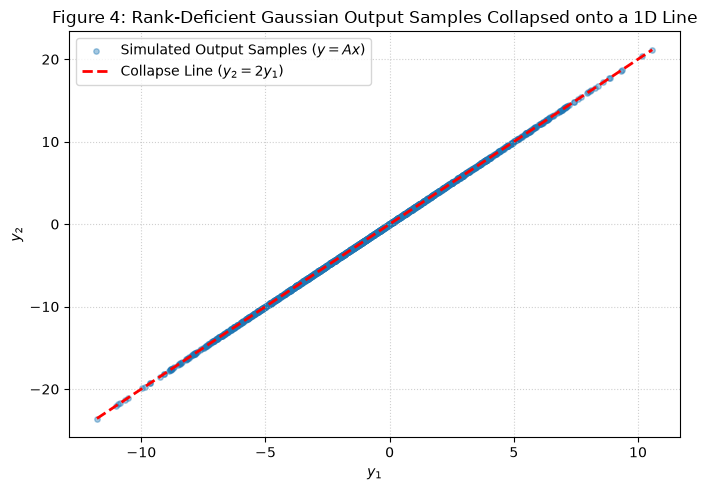

In [116]:
# Figure 4 generation

fig4 = plt.figure(figsize=(7, 5))
subset = Y2[:2000]
plt.scatter(subset[:, 0], subset[:, 1], alpha=0.4, s=15, label="Simulated Output Samples ($y = Ax$)")

# Plot the collapse line y2 = 2*y1
x_line = np.linspace(subset[:, 0].min(), subset[:, 0].max(), 100)
plt.plot(x_line, 2 * x_line, color="red", linestyle="--", linewidth=2, label="Collapse Line ($y_2 = 2y_1$)")

plt.title("Figure 4: Rank-Deficient Gaussian Output Samples Collapsed onto a 1D Line")
plt.xlabel("$y_1$")
plt.ylabel("$y_2$")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
# plt.close(fig4)

## Step 5

## Step 6

## Step 7

## Step 8

## Bonus A

## Bonus B

In [ ]:
_end_time = time.perf_counter()
print(f"Total Notebook Runtime: {_end_time - _start_time:.3f} seconds")